# The LGD ladder: OLS, fractional logit, beta, hurdle, boosting and Tobit

**Question:** Which of six model forms for the loss given default of small-business loans ranks and calibrates best out of time, and what does the calibration gap show that the R-squared hides?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic (the workout LGD and the C08 proxy)
- **Reading time:** about 60 minutes

## Objectives

By the end of this notebook you can:

- write the specification of each rung of the C08 ladder (OLS, fractional logit, beta, hurdle, gradient boosting, Tobit) and say what its prediction means;
- rebuild a fitted rung from the coefficients committed in the artifact and predict with the engine's `predict_lgd`, so a committed model is re-usable and checkable;
- refit the five engine rungs with `fit_ols`, `fit_fractional_logit`, `fit_beta`, `fit_hurdle` and `fit_tobit` on a sample whose truth is known, and read what each recovers;
- explain why the beta rung depends on an endpoint adjustment, and read the committed sensitivity to it;
- compare the rungs out of time on the six default cohorts of C08, by R-squared, rank correlation and calibration gap, and say what the calibration gap shows that the R-squared does not.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you.

In [1]:
# Import the tools and print their versions, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.lgd_ead import lgd_models as lm

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Data

Seven committed artifacts of case C08, the loss given default of small-business loans after default. One is the model artifact `models-dc-2007-08.json`, which holds the fitted ladder (the coefficients, the standardisation, the settings). The other six are the variants `dc-2003-06.json` to `dc-2020-23.json`, one per default cohort, which hold each rung's out-of-time results: R-squared, rank correlation, the calibration gap, the calibration by bucket and the engine's test rows.

The design follows the leakage rules of the research. The ladder is fitted once, on the defaults whose charge-off closed strictly before the cutoff of 31 December 2006, and each cohort from 2007 on is a test the fit has never seen. The target is the charge-off proxy of notebook 01, so everything below is a statement about the proxy and not about a workout LGD. The artifacts were baked by an older engine than the installed one, and the next cell prints both versions.

In [2]:
# Open the model artifact and the six cohort variants, and list the rungs with their library
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived" / "C08"
models = json.loads((DERIVED / "models-dc-2007-08.json").read_text(encoding="utf-8"))
COHORTS = ["2003-06", "2007-08", "2009-10", "2011-13", "2014-19", "2020-23"]
cohort = {c: json.loads((DERIVED / f"dc-{c}.json").read_text(encoding="utf-8")) for c in COHORTS}
fit = models["fit"]
print("model artifact baked by riskvalidation:", models["provenance"]["riskvalidation_version"])
print("installed:", rv.__version__)
print("training cutoff:", fit["training"]["cutoff_date"], "|", f"{fit['training']['n_defaults']:,}")
for rung in fit["ladder"]:
    print(f"{rung['rung_id'][:2]} {rung['library']} {rung['library_version']} | covariates {len(rung['covariates'])}")

model artifact baked by riskvalidation: 1.0.1
installed: 1.0.1
training cutoff: 2006-12-31 | 48,833
L1 riskvalidation 1.0.1 | covariates 16
L2 riskvalidation 1.0.1 | covariates 16
L3 riskvalidation 1.0.1 | covariates 16
L4 riskvalidation 1.0.1 | covariates 16
L5 catboost 1.2.10 | covariates 16
L6 riskvalidation 1.0.1 | covariates 16


## Method

### Step 1: the six rungs and what each predicts

All six rungs predict the mean LGD of a loan given its covariates $x$ (the logarithm of the amount and of the term, the guaranteed and seasoning shares, a revolver flag and the sector dummies), with an intercept column. The engine's `lgd_models` module implements five of them in pure NumPy and SciPy; the sixth is the pipeline's gradient-boosted challenger.

| Rung | Specification | Prediction |
|---|---|---|
| L1 OLS | $y = x'\beta + \varepsilon$ | $\hat y = \min(\max(x'\beta, 0), 1)$, clipped only at prediction |
| L2 fractional logit | $E[y \mid x] = 1 / (1 + e^{-x'\beta})$, Bernoulli quasi-likelihood (Papke and Wooldridge 1996) | $\hat y = 1 / (1 + e^{-x'\beta})$ |
| L3 beta | $y \sim \mathrm{Beta}(\mu\varphi, (1-\mu)\varphi)$, $\mu = 1 / (1 + e^{-x'\beta})$, $\mathrm{Var}(y) = \mu(1-\mu)/(1+\varphi)$ (Ferrari and Cribari-Neto 2004), fitted on $\min(\max(y, \epsilon), 1-\epsilon)$ | $\hat y = \mu$ |
| L4 hurdle | stage 1: $P(y>0 \mid x) = 1/(1+e^{-x'\gamma})$; stage 2: $E[y \mid y>0, x] = 1/(1+e^{-x'\delta})$ among the loans with $y > 0$ (Leow and Mues 2012; Tong, Mues and Thomas 2013) | $\hat y = P(y>0 \mid x)\,E[y \mid y>0, x]$ |
| L5 gradient boosted | CatBoost with the cross-entropy loss, 200 trees of depth 6 | the model's output, in [0, 1] |
| L6 Tobit | $y = \min(1, \max(0, y^*))$, $y^* = x'\beta + \varepsilon$, $\varepsilon \sim N(0, \sigma^2)$ (Tobin 1958) | $E[y \mid x]$ of the censored normal, in closed form |

(Sources: the docstrings of `riskvalidation.lgd_ead.lgd_models` at release 0.8.1, which name the authors above; the gradient-boosting settings are printed by the data cell.) Two properties matter for what follows. OLS can predict outside [0, 1], so its prediction is clipped, which is a choice of the engine. The beta rung cannot take the values 0 and 1 exactly, so it needs the endpoint adjustment $\epsilon$ of step 4. The data cell above lists them with their library.

### Step 2: the committed coefficients

A linear rung is its coefficients plus the standardisation of its four continuous covariates (each is centred and scaled with the mean and standard deviation of the training slice, so that the coefficients are comparable). The artifact keeps both. OLS lives on the LGD scale and the fractional logit and Tobit on their own link, so their raw numbers cannot be laid side by side; the cell divides each rung's slopes by its largest absolute slope and draws them, which compares sign and relative weight. A coefficient on a standardised covariate is the change of the linear predictor per standard deviation; the revolver flag and the sector dummies enter as 0 or 1.

standardisation of log_amount       mean  11.3042  standard deviation  1.1594
standardisation of log_term         mean   3.8940  standard deviation  0.9383
standardisation of guaranteed_share mean   0.7518  standard deviation  0.1358
standardisation of seasoning_share  mean   0.8478  standard deviation  0.4847
defaults fitted: 47,726


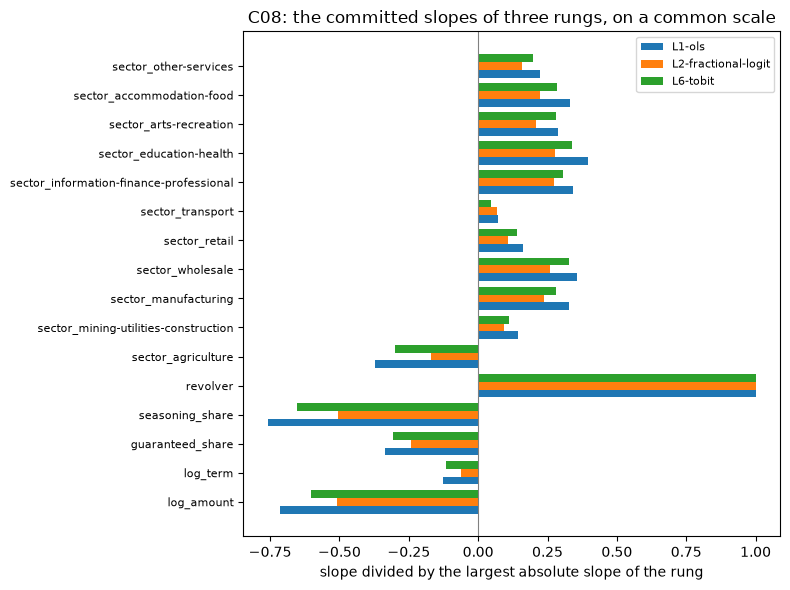

In [3]:
# Draw the slopes of three committed rungs, each scaled by its largest absolute slope
ladder = {r["rung_id"]: r for r in fit["ladder"]}
detail = {m["id"]: m["details"] for m in models["model"]}
coefs = {rid: np.array([c["estimate"] for c in r["coefficients"]]) for rid, r in ladder.items() if r["coefficients"]}
terms = [c["name"] for c in ladder["L1-ols"]["coefficients"]][1:]
standard = detail["L2-fractional-logit"]["standardisation"]
for name, s in standard.items():
    print(f"standardisation of {name:16s} mean {s['mean']:8.4f}  standard deviation {s['std']:7.4f}")
print("defaults fitted:", f"{detail['L2-fractional-logit']['n_fitted']:,}")

fig, ax = plt.subplots(figsize=(8, 6))
rows = np.arange(len(terms))
for k, rid in enumerate(("L1-ols", "L2-fractional-logit", "L6-tobit")):
    scaled = coefs[rid][1:] / np.abs(coefs[rid][1:]).max()
    ax.barh(rows + (k - 1) * 0.27, scaled, height=0.27, label=rid)
ax.set_yticks(rows)
ax.set_yticklabels(terms, fontsize=8)
ax.axvline(0.0, color="grey", linewidth=0.8)
ax.set_xlabel("slope divided by the largest absolute slope of the rung")
ax.set_title("C08: the committed slopes of three rungs, on a common scale")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The three rungs agree on direction almost everywhere: the logarithm of the amount, the guaranteed share and the seasoning share push the expected loss down, the revolver flag pushes it up, and the sector dummies move in the same way for OLS, the fractional logit and the Tobit. What changes between rungs is the relative weight, not the story, which is why the ranking metrics of step 6 are close to one another while the levels are not. The figure compares slopes only; it says nothing yet about how well any rung predicts, which needs the cohorts the fit never saw.

### Step 3: predict with the engine from the committed coefficients

The engine's `LgdFit` holds exactly what the artifact stores, so a committed rung can be rebuilt and used: `LgdFit(kind, names, coefficients, extras)`. The extras are the beta precision $\varphi$ and endpoint $\epsilon$, the two hurdle coefficient vectors, and the Tobit $\sigma$. `predict_lgd(fit, X)` then returns the prediction, with only the OLS one clipped.

The first cell builds the design matrix of three invented loans (a small revolving line in retail, a mid-size manufacturing loan, a large long-term agricultural loan) by applying the committed standardisation. The covariate values are made up to illustrate the arithmetic; they are not loans of the file.

In [4]:
# Build the design matrix of three invented loans with the committed standardisation
covariates = ladder["L2-fractional-logit"]["covariates"]
invented = [  # amount, term in months, guaranteed share, seasoning share, revolver, sector
    (50_000, 24, 0.50, 0.30, 1, "retail"),
    (350_000, 84, 0.75, 1.00, 0, "manufacturing"),
    (1_500_000, 240, 0.75, 1.00, 0, "agriculture"),
]
rows = []
for amount, term, guaranteed, seasoning, revolver, sector in invented:
    raw = {"log_amount": np.log(amount), "log_term": np.log(term)}
    raw.update(guaranteed_share=guaranteed, seasoning_share=seasoning)
    row = [1.0]
    for name in covariates:
        if name in raw:
            row.append((raw[name] - standard[name]["mean"]) / standard[name]["std"])
        elif name == "revolver":
            row.append(float(revolver))
        else:
            row.append(1.0 if name == f"sector_{sector}" else 0.0)
    rows.append(row)
X = np.array(rows)
print("design matrix:", X.shape, "| first row:", np.round(X[0], 3))

design matrix: (3, 17) | first row: [ 1.    -0.418 -0.763 -1.854 -1.13   1.     0.     0.     0.     0.
  1.     0.     0.     0.     0.     0.     0.   ]


The second cell rebuilds five rungs as `LgdFit` objects from the committed numbers and predicts the three loans, followed by the two stages of the hurdle rung.

In [5]:
# Rebuild five committed rungs as LgdFit, predict the three loans and open the two stages of one
names = ("const", *covariates)
two = detail["L4-hurdle"]
stage1_coef = np.array(two["stage1_coefficients"])
extras_beta = {"phi": detail["L3-beta"]["phi"], "epsilon": ladder["L3-beta"]["epsilon"]}
extras_two = {"stage1_coefficients": stage1_coef, "severity_columns": tuple(two["severity_columns"])}
rebuilt = {
    "L1 OLS": lm.LgdFit("ols", names, coefs["L1-ols"]),
    "L2 fractional logit": lm.LgdFit("fractional-logit", names, coefs["L2-fractional-logit"]),
    "L3 beta": lm.LgdFit("beta", names, coefs["L3-beta"], extras_beta),
    "L4 hurdle": lm.LgdFit("hurdle", names, coefs["L4-hurdle"], extras_two),
    "L6 Tobit": lm.LgdFit("tobit", names, coefs["L6-tobit"], {"sigma": detail["L6-tobit"]["sigma"]}),
}
print(f"{'':36s} " + " ".join(f"loan {k}".rjust(11) for k in (1, 2, 3)))
for label, f in rebuilt.items():
    print(f"{label:36s} " + " ".join(f"{p:11.4f}" for p in lm.predict_lgd(f, X)))
stage1 = 1 / (1 + np.exp(-(X @ stage1_coef)))
stage2 = 1 / (1 + np.exp(-(X @ coefs["L4-hurdle"])))
print(f"{'stage 1: P(y > 0)':36s} " + " ".join(f"{p:11.4f}" for p in stage1))
print(f"{'stage 2: E[y | y > 0]':36s} " + " ".join(f"{p:11.4f}" for p in stage2))
print(f"{'stage 1 times stage 2':36s} " + " ".join(f"{p:11.4f}" for p in stage1 * stage2))

                                          loan 1      loan 2      loan 3
L1 OLS                                    0.9467      0.5396      0.3590
L2 fractional logit                       0.9127      0.5328      0.3326
L3 beta                                   0.9057      0.5363      0.3424
L4 hurdle                                 0.9126      0.5332      0.3287
L6 Tobit                                  0.8972      0.5369      0.3596
stage 1: P(y > 0)                         1.0000      0.9948      0.9768
stage 2: E[y | y > 0]                     0.9127      0.5360      0.3365
stage 1 times stage 2                     0.9126      0.5332      0.3287


The five rungs agree on the ordering of the three loans, and they differ most on the first, which sits near the top of the range. That is where the choice of the link matters: OLS gives 0.9467 and the Tobit expectation 0.8972, with the logistic forms between them. The last three rows reproduce the engine's hurdle prediction by hand from its two stages; stage 1 is close to 1, that is, when nearly every default loses something the "loss or not" stage carries little information and the hurdle stays close to the fractional logit.

### Step 4: the endpoint adjustment of the beta rung

The beta density is zero or infinite at 0 and 1, so the beta rung is fitted on $y_\epsilon = \min(\max(y, \epsilon), 1-\epsilon)$, which `endpoint_transform(y, epsilon)` computes. Qi and Zhao (2011), as the engine's docstring records, found beta results very sensitive to this small number, and C08 reports the sensitivity instead of hiding it: `outputs.endpoint_sensitivity` holds, for three values of $\epsilon$, the mean prediction and the RMSE on the cohort. The cell applies the transform to five values and prints the committed sensitivity, with the values of $\varphi$ the artifact reports for the three refits.

In [6]:
# Apply the endpoint transform to five values and print the committed sensitivity to epsilon
sample = np.array([0.0, 0.2, 0.5, 0.97, 1.0])
for eps in (0.0001, 0.001, 0.01):
    print(f"epsilon={eps:<7}", lm.endpoint_transform(sample, eps))
print()
sens = cohort["2007-08"]["outputs"]["endpoint_sensitivity"]
print(f"{'epsilon':>8s} {'mean prediction':>26s} {'RMSE':>8s}")
for row in sens:
    print(f"{row['epsilon']:8.4f} {row['mean_predicted']['value']:26.4f} {row['rmse']:8.4f}")
print("beta precision phi of the committed fit (epsilon 0.001):", round(detail["L3-beta"]["phi"], 4))

epsilon=0.0001  [1.000e-04 2.000e-01 5.000e-01 9.700e-01 9.999e-01]
epsilon=0.001   [0.001 0.2   0.5   0.97  0.999]
epsilon=0.01    [0.01 0.2  0.5  0.97 0.99]

 epsilon            mean prediction     RMSE
  0.0001                     0.7568   0.2928
  0.0010                     0.7503   0.2942
  0.0100                     0.7402   0.2970
beta precision phi of the committed fit (epsilon 0.001): 2.7105


The mean prediction of the beta rung moves with $\epsilon$ while the RMSE barely does: a modeller who picks $\epsilon$ for the best RMSE is also picking a level. A validator should ask for the sensitivity and for the calibration gap at the chosen value, which is what steps 6 and 7 look at.

### Step 5: refit the engine rungs on a sample whose truth is known

The committed artifact keeps the fitted coefficients but not the 47,726 training loans (the SBA file is a third-party dataset that is not committed), so the fits cannot be repeated on the real data here. To see the engine's `fit_*` functions work, the next cell generates a small sample in the notebook, **a toy with a known truth, not a case**: 4,000 loans, two covariates, a body of beta-distributed losses, 18% cures at exactly 0 and 8% total losses at exactly 1. Nothing is read from a file and nothing is written; the seed is fixed. It then fits the five engine rungs on the same design and reports the mean prediction, the RMSE against the realised value and the R-squared.

What to look for: the mean of the realised LGD is the target level, and a well-calibrated rung reproduces it. OLS with an intercept and the logistic quasi-likelihood do so by their own estimating equations; the other rungs need not, and the beta rung is fitted on the endpoint-adjusted values.

In [7]:
# Generate a toy sample with a known truth and fit the five engine rungs on it
rng = np.random.default_rng(20261021)
n = 4000
x1, x2 = rng.normal(size=n), rng.normal(size=n)
Xt = np.column_stack([np.ones(n), x1, x2])
mu = 1 / (1 + np.exp(-(0.4 + 0.8 * x1 - 0.5 * x2)))
body = rng.beta(mu * 4.0, (1 - mu) * 4.0)
y = np.where(rng.random(n) < 0.18, 0.0, np.where(rng.random(n) < 0.08 / 0.82, 1.0, body))
print(f"toy sample: n={n} | share at 0={np.mean(y == 0):.3f} | share at 1={np.mean(y == 1):.3f}")
print(f"mean realised LGD={y.mean():.4f}")

toy = {
    "L1 OLS": lm.fit_ols(Xt, y),
    "L2 fractional logit": lm.fit_fractional_logit(Xt, y),
    "L3 beta (epsilon 0.001)": lm.fit_beta(Xt, y, 0.001),
    "L4 two-stage": lm.fit_hurdle(Xt, y),
    "L6 Tobit": lm.fit_tobit(Xt, y),
}
print(f"{'':34s} {'mean prediction':>24s} {'RMSE':>8s} {'R-squared':>10s}")
for label, f in toy.items():
    p = lm.predict_lgd(f, Xt)
    r2 = 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)
    print(f"{label:34s} {p.mean():24.4f} {np.sqrt(np.mean((y - p) ** 2)):8.4f} {r2:10.4f}")

toy sample: n=4000 | share at 0=0.167 | share at 1=0.083
mean realised LGD=0.5217
                                            mean prediction     RMSE  R-squared
L1 OLS                                               0.5217   0.3272     0.1480
L2 fractional logit                                  0.5217   0.3270     0.1486
L3 beta (epsilon 0.001)                              0.4881   0.3342     0.1109
L4 two-stage                                         0.5219   0.3272     0.1479
L6 Tobit                                             0.5033   0.3291     0.1379


The table tells the level story in numbers; the next cell draws it. It cuts the toy sample into ten groups by the first covariate and plots, for each rung, the mean prediction of the group against the mean realised LGD of the same group, so that a rung that gets the slope right but the level wrong shows as a parallel line.

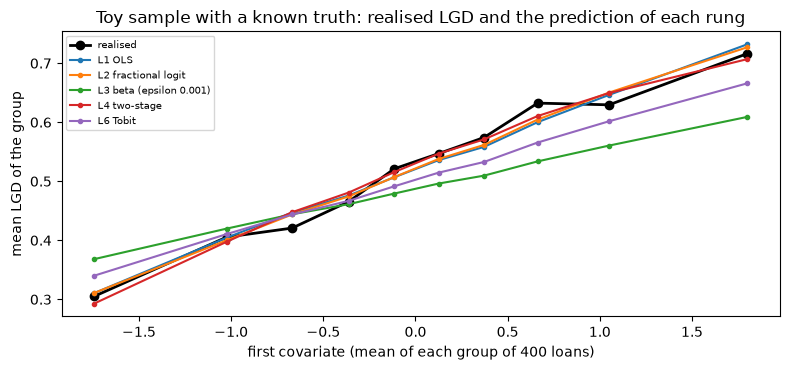

In [8]:
# Draw the mean prediction of each rung and the mean realised LGD in ten groups of the first covariate
groups = np.array_split(np.argsort(x1), 10)
centre = [x1[g].mean() for g in groups]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(centre, [y[g].mean() for g in groups], "k-o", linewidth=2, label="realised")
for label, f in toy.items():
    pred = lm.predict_lgd(f, Xt)
    ax.plot(centre, [pred[g].mean() for g in groups], marker=".", label=label)
ax.set_xlabel("first covariate (mean of each group of 400 loans)")
ax.set_ylabel("mean LGD of the group")
ax.set_title("Toy sample with a known truth: realised LGD and the prediction of each rung")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

All five curves follow the realised curve in shape: they rise with the covariate and flatten at the ends, which the logistic forms do by construction and OLS does inside the clipping. The vertical offset is where they differ. OLS, the fractional logit and the two-stage rung sit on the realised line, the beta rung runs below it over the whole range, and the Tobit expectation sits slightly under at the high end. That offset is the level error of the table, now seen as a function of the covariate: a rung can order the loans correctly and still place them all too low, which is the pattern the out-of-time cohorts show below.

Now the sensitivity of the beta rung to $\epsilon$ on this toy, refitting three times, and the cure decomposition of the research, $E[LGD] = P_{cure}\,LGD_{cure} + (1 - P_{cure})\,LGD_{liq}$, which `cure_decomposition` computes. It is the practitioner decomposition; the engine marks its single academic source UNVERIFIED, so the notebook states the identity and cites no author. The cell uses the toy sample and invented probabilities.

In [9]:
# Refit the beta rung at three values of epsilon and apply the cure decomposition to invented inputs
print(f"realised mean on the toy: {y.mean():.4f}")
for eps in (0.0001, 0.001, 0.01):
    f = lm.fit_beta(Xt, y, eps)
    print(f"epsilon={eps:<7} mean prediction {lm.predict_lgd(f, Xt).mean():.4f}  phi {f.extras['phi']:.4f}")
p_cure = np.array([0.30, 0.50])
cure = lm.cure_decomposition(p_cure, np.array([0.05, 0.10]), np.array([0.60, 0.70]))
print("cure decomposition for P_cure 0.30 and 0.50 (LGD_cure 0.05 and 0.10, LGD_liq 0.60 and 0.70):", cure)

realised mean on the toy: 0.5217
epsilon=0.0001  mean prediction 0.4776  phi 0.6375
epsilon=0.001   mean prediction 0.4881  phi 0.8141
epsilon=0.01    mean prediction 0.5022  phi 1.1691
cure decomposition for P_cure 0.30 and 0.50 (LGD_cure 0.05 and 0.10, LGD_liq 0.60 and 0.70): [0.435 0.4  ]


### Step 6: out of time, on the six cohorts

Back to the real ladder. Each cohort variant holds `outputs.rung_comparison`, the out-of-time scores of every rung on that cohort: R-squared, RMSE, MAE, Spearman rank correlation and the calibration gap (the mean realised value of the indicator minus the mean predicted). The figure draws the R-squared and the calibration gap of every rung by cohort. A rung that could not be evaluated on a cohort has no point there. The calibration gap is the figure the research and the engine's tests point to beside the R-squared, because R-squared is low for every LGD model (Loterman et al. 2012, as the engine's docstring reports, found average R-squared between 4% and 43%).

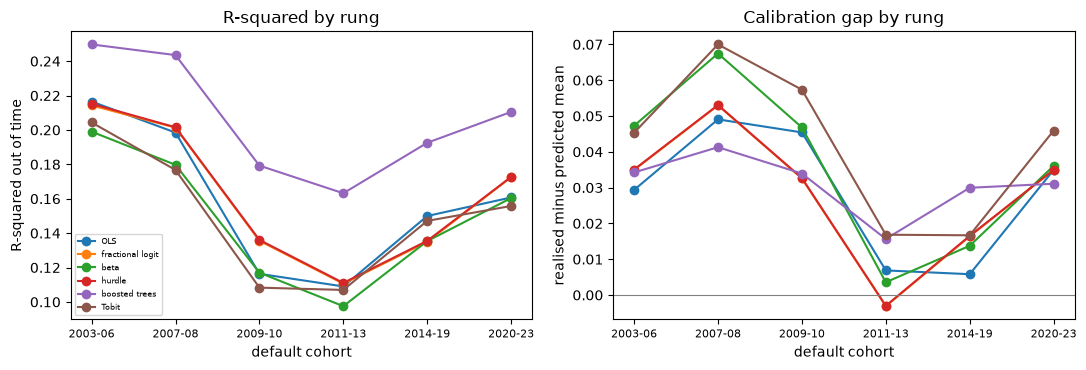

In [10]:
# Draw the R-squared and the calibration gap of every rung on each of the six cohorts
score = {c: {r["rung_id"]: r for r in cohort[c]["outputs"]["rung_comparison"]} for c in COHORTS}
short = {"L1-ols": "OLS", "L2-fractional-logit": "fractional logit", "L3-beta": "beta",
         "L4-hurdle": "hurdle", "L5-gradient-boosted": "boosted trees", "L6-tobit": "Tobit"}
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8))
for rung in ladder:
    where = [c for c in COHORTS if rung in score[c]]
    xs = [COHORTS.index(c) for c in where]
    left.plot(xs, [score[c][rung]["r2"] for c in where], marker="o", label=short[rung])
    right.plot(xs, [score[c][rung]["calibration_gap"] for c in where], marker="o", label=short[rung])
right.axhline(0.0, color="grey", linewidth=0.8)
for ax, ylabel in ((left, "R-squared out of time"), (right, "realised minus predicted mean")):
    ax.set_xticks(range(len(COHORTS)))
    ax.set_xticklabels(COHORTS, fontsize=8)
    ax.set_xlabel("default cohort")
    ax.set_ylabel(ylabel)
left.set_title("R-squared by rung")
right.set_title("Calibration gap by rung")
left.legend(fontsize=6)
fig.tight_layout()
plt.show()

The left panel shows the ranking that R-squared gives: the boosted rung is on top in every cohort, the five parametric rungs bunch together below it, and all the values stay low, between about 0.10 and 0.25. The right panel is the other criterion. Nearly every point is above zero, so the realised indicator exceeds the prediction almost everywhere, and the boosted rung, best on the left, is not systematically the closest to zero on the right. The next cell counts both statements.

In [11]:
# Count the cohorts where the best R-squared is also the smallest absolute gap, and the positive gaps
all_r2 = [r["r2"] for c in COHORTS for r in score[c].values()]
gaps = [r["calibration_gap"] for c in COHORTS for r in score[c].values()]
print(f"rung-cohort scores: {len(all_r2)} | R-squared from {min(all_r2):.4f} to {max(all_r2):.4f}")
print(f"positive calibration gaps (realised above predicted): {sum(g > 0 for g in gaps)} of {len(gaps)}")
same = 0
for c in COHORTS:
    best_r2 = max(score[c], key=lambda k: score[c][k]["r2"])
    best_gap = min(score[c], key=lambda k: abs(score[c][k]["calibration_gap"]))
    same += best_r2 == best_gap
    print(f"{c}: best R-squared {short[best_r2]:18s} | smallest absolute gap {short[best_gap]}")
print(f"cohorts where both coincide: {same} of {len(COHORTS)}")
absent = [(c, rid) for c in COHORTS for rid in ladder if rid not in score[c]]
print("rungs absent from a cohort comparison:", [(c, short[r]) for c, r in absent])

rung-cohort scores: 36 | R-squared from 0.0975 to 0.2497
positive calibration gaps (realised above predicted): 34 of 36
2003-06: best R-squared boosted trees      | smallest absolute gap OLS
2007-08: best R-squared boosted trees      | smallest absolute gap boosted trees
2009-10: best R-squared boosted trees      | smallest absolute gap fractional logit
2011-13: best R-squared boosted trees      | smallest absolute gap hurdle
2014-19: best R-squared boosted trees      | smallest absolute gap OLS
2020-23: best R-squared boosted trees      | smallest absolute gap boosted trees
cohorts where both coincide: 2 of 6
rungs absent from a cohort comparison: []


### Step 7: calibration by bucket and the engine's tests

The mean can be right while the shape is wrong, so each cohort also holds `calibration_by_bucket`: the loans of the cohort are cut into five equal groups by predicted LGD, and for each group the mean predicted and the mean realised value. A well-calibrated rung lies on the diagonal. The cell draws the 2007-08 cohort for the fractional-logit rung and the boosted rung.

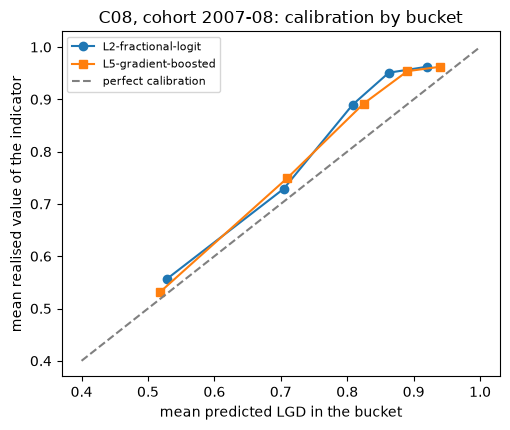

In [12]:
# Draw the calibration by bucket of two rungs on the cohort 2007-08
o = cohort["2007-08"]["outputs"]
fig, ax = plt.subplots(figsize=(5.2, 4.4))
for rung_id, marker in (("L2-fractional-logit", "o"), ("L5-gradient-boosted", "s")):
    buckets = [x for x in o["calibration_by_bucket"] if x["rung_id"] == rung_id]
    predicted = [x["predicted"]["value"] for x in buckets]
    realised = [x["realised"]["value"] for x in buckets]
    ax.plot(predicted, realised, marker=marker, label=rung_id)
ax.plot([0.4, 1.0], [0.4, 1.0], color="grey", linestyle="--", label="perfect calibration")
ax.set_xlabel("mean predicted LGD in the bucket")
ax.set_ylabel("mean realised value of the indicator")
ax.set_title("C08, cohort 2007-08: calibration by bucket")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Both curves lie above the diagonal in every bucket: where the rung predicts 0.5 the realised value is higher, and the distance is largest in the middle buckets rather than at the extremes. The boosted rung is closer to the diagonal than the fractional logit, in line with its smaller gap, and still not on it. This is the shape behind a positive mean gap: it is a level error across the whole range of predictions and not an artefact of a few extreme loans. The engine's own tests turn the gap into a light, and the next cell prints their committed rows.

In [13]:
# Print the engine's committed test rows for the cohort 2007-08 of two rungs
light = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}
print("baked by riskvalidation:", cohort["2007-08"]["provenance"]["riskvalidation_version"])
shown = ("L2-fractional-logit", "L5-gradient-boosted")
for t in cohort["2007-08"]["tests"]:
    if t["model_id"] in shown and t["test_id"] != "lgd_ead.downturn_coverage":
        p = "n/a" if t["p_value"] is None else f"{t['p_value']:.3g}"
        print(f"{t['test_id'][8:]:30s} {t['model_id']:21s} {light[t['light']]:8s} metric {t['metric']:.4f}  p {p}")

baked by riskvalidation: 1.0.1
lgd_calibration_by_segment     L2-fractional-logit   red      metric 0.0530  p 2.78e-188
lgd_discrimination             L2-fractional-logit   green    metric 0.6301  p 0
lgd_calibration_over_time      L2-fractional-logit   red      metric 0.0748  p 8.61e-147
lgd_calibration_by_segment     L5-gradient-boosted   red      metric 0.0413  p 8.58e-121
lgd_discrimination             L5-gradient-boosted   green    metric 0.6762  p 0
lgd_calibration_over_time      L5-gradient-boosted   red      metric 0.0947  p 6.23e-219


## Results

**Answer:** Out of time, on the six default cohorts of C08, the boosted rung has the highest R-squared in all six, yet every R-squared stays between 0.0975 and 0.2497, the rung with the smallest calibration gap is the one with the highest R-squared in only 2 of the 6 cohorts, and in 34 of the 36 rung-cohort scores the realised indicator is above the prediction. On a toy sample whose mean is 0.5217, OLS, the fractional logit and the two-stage rung reproduce it (0.5217, 0.5217 and 0.5219) with R-squared between 0.1479 and 0.1486, while the beta rung gives 0.4881: the level, not the R-squared, is what separates the rungs.

- **A committed rung is a model you can run.** From the committed coefficients and standardisation alone, `LgdFit` and `predict_lgd` give the fractional logit's LGD for the three invented loans: 0.9127, 0.5328 and 0.3326. The two stages of the two-stage rung multiply back to its own prediction (0.9126, 0.5332 and 0.3287), with stage 1 at 1.0000, 0.9948 and 0.9768.
- **The beta rung depends on the endpoint adjustment.** On the committed cohort 2007-08 its mean prediction is 0.7568, 0.7503 and 0.7402 for $\epsilon$ equal to 0.0001, 0.001 and 0.01, while the RMSE moves from 0.2928 to 0.2970. On the toy the same three values give 0.4776, 0.4881 and 0.5022 against a realised mean of 0.5217.
- **Out of time, the best R-squared is not always the best calibration.** The boosted rung has the highest R-squared in all six cohorts and the smallest absolute gap in 2 of them (2007-08 and 2020-23); the smallest gap belongs to OLS in 2003-06 and 2014-19, to the fractional logit in 2009-10 and to the two-stage rung in 2011-13. All six rungs were evaluated on all six cohorts.
- **The engine's tests turn the gap into a light.** On 2007-08 the fractional logit (gap 0.0530) and the boosted rung (0.0413) are red on calibration and green on discrimination (Spearman 0.6301 and 0.6762): the ranking works and the level is too low, for an indicator whose bias direction the artifact states.

What the notebook does not do: it does not refit the ladder on the real SBA loans, which are not committed, and it does not name a best rung. The toy sample is generated in the notebook to show the fits and has no relation to any lender.

## Summary

- Six rungs, one target: OLS clipped at prediction, fractional logit (quasi-likelihood), beta on adjusted endpoints, a two-stage hurdle, boosted trees and Tobit. The engine implements five, and the committed artifact stores their coefficients and extras, so any of them can be rebuilt as an `LgdFit` and used with `predict_lgd`.
- On a toy sample with a known truth the R-squared of the rungs is close and their calibration is not; the beta rung moves with the endpoint adjustment, which C08 reports as a sensitivity.
- Out of time, on the six cohorts of C08, the R-squared is low for every rung and the rung with the highest R-squared is the best calibrated in only some cohorts, so the calibration gap is a second criterion. The engine's tests turn the gap into a light with its p-value and the version that baked it.
- Everything here is about the charge-off proxy of C08, not a workout LGD.

**What to try next.** Rebuild the L3 beta rung with the other two values of $\epsilon$ reported in `epsilons_reported` of the artifact and compare its predictions for the three invented loans; then continue with notebook 04, which asks what a downturn does to these LGDs and where the regulatory floors bite.

## References

- Papke, L. E. and Wooldridge, J. M. (1996), the Bernoulli quasi-likelihood for fractional responses (the fractional logit), as named in the engine's documentation of `riskvalidation.lgd_ead.lgd_models`.
- Ferrari, S. L. P. and Cribari-Neto, F. (2004), beta regression with a logit mean link and a log precision link, as named in the same docstring.
- Leow, M. and Mues, C. (2012) and Tong, E. N. C., Mues, C. and Thomas, L. C. (2013), the two-stage (hurdle) LGD model, as named in the docstring of `fit_hurdle`.
- Tobin, J. (1958), the censored normal regression, as named in the docstring of `fit_tobit`.
- Loterman, G., Brown, I., Martens, D., Mues, C. and Baesens, B. (2012), Benchmarking regression algorithms for loss given default modeling, International Journal of Forecasting 28(1). https://doi.org/10.1016/j.ijforecast.2011.01.006
- Qi, M. and Zhao, X. (2011), Comparison of modeling methods for loss given default, Journal of Banking and Finance 35(11). https://doi.org/10.1016/j.jbankfin.2011.03.011
- BCBS, Basel Framework, CRE32 (internal ratings-based approach; the LGD input floors are applied in notebook 04). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/32/inforce/2023-01-01/published/2020-03-27
- This repository: `docs/design/SDD.md` (case C08) and `data/derived/C08/` (the model artifact and the six cohort variants).